# Missing data and time patterns — Code-Along Template

**Type into this notebook during class.** The explanation is here; the code is not.

| | |
|---|---|
| **Follow along** | Write the code in each `# TODO` cell. The hint names the functions and arguments. |
| **If you fall behind** | Do not copy frantically. Skip to the next **CHECKPOINT**, run it, rejoin. |
| **If a cell errors** | Later cells depend on it and will fail too. Run the next CHECKPOINT rather than debugging under time pressure. |
| **After class** | The worked version is `D005_02c_Time_Patterns.ipynb`. Compare, do not copy. |

Cells that are already filled in are deliberate — imports and quick glances at the
data cost class time and teach nothing.

# C3: Python Patterns Over Time

## Learning Objectives

By the end of this notebook, you will be able to:
- Convert and work with datetime objects in Python
- Extract temporal features (Year, Month, Day, Day of Week)
- Visualize long-term trends using line plots
- Analyze seasonal and cyclical patterns
- Apply rolling statistics (Moving Averages) to smooth noise
- Analyze derived time-based metrics (Marriage Duration, Age at Marriage)

---

## 1. Introduction to Time-Based Analysis

Time is one of the most critical dimensions in data analysis. Trends, seasonality, and cycles can reveal insights that simple aggregates miss.

**Key Components of Time Series:**
1. **Trend**: Long-term direction (increasing, decreasing, stable).
2. **Seasonality**: Repeating patterns over a fixed period (e.g., more sales in December).
3. **Cycles**: Fluctuations that don't follow a fixed period (e.g., economic boom/bust).
4. **Irregularity/Noise**: Random fluctuations.

### Time Series Components Visualized

**Trend - Long-term direction:**
![Trend in Time Series](https://media.geeksforgeeks.org/wp-content/uploads/20230205011801/trend-in-time-series.png)

**Seasonality - Fixed periodic patterns:**
![Seasonality in Time Series](https://media.geeksforgeeks.org/wp-content/uploads/20230205013407/sesonality-in-time-series.png)

**Cyclicity - Variable-length fluctuations:**
![Cyclicity in Time Series](https://media.geeksforgeeks.org/wp-content/uploads/20230205014702/cyclicity-in-time-series.png)

*Source: GeeksforGeeks - Components of Time Series Data*

---

## 2. Environmental Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Settings
plt.style.use('seaborn-v0_8-darkgrid')
pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")

Libraries imported successfully!


---

## 3. Data Loading and Date Preparation

We use the **Divorce Data Analysis** dataset.

### Load Data

In [ ]:
# TODO: compute `df`
# Hint: pd.read_csv, df.head
# Name your result: df

In [ ]:
# ═══ CHECKPOINT — "Convert Date Columns" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('../../00-data/Divorce Data Analysis.csv')

print("Checkpoint restored. Ready for: Convert Date Columns")

### Convert Date Columns

Columns like `divorce_date`, `dob_man`, etc., are often read as strings (object type). We must convert them to `datetime` objects to perform time-based operations.

In [ ]:
# TODO: compute `date_cols`
# Hint: pd.to_datetime
# Name your result: date_cols

### Extract Features

We extract components like Year and Month to analyze trends.

In [4]:
# Extract Year and Month from Divorce Date
df['divorce_year'] = df['divorce_date'].dt.year
df['divorce_month'] = df['divorce_date'].dt.month_name()
df['divorce_day_of_week'] = df['divorce_date'].dt.day_name()

# Extract Year from Marriage Date
df['marriage_year'] = df['marriage_date'].dt.year
df['marriage_month'] = df['marriage_date'].dt.month_name()

df[['divorce_date', 'divorce_year', 'divorce_month']].head()

,divorce_date,divorce_year,divorce_month
0,2006-09-06,2006,September
1,2008-01-02,2008,January
2,2011-01-02,2011,January
3,2011-01-02,2011,January
4,2011-01-02,2011,January


---

## 4. Trend Analysis (Long-term)

Let's visualize the number of divorces per year to see the long-term trend.

In [ ]:
# TODO: draw a `plt.figure` of `divorce_year`
# Hint: plt.figure, .sort_index(), sns.lineplot, plt.title, plt.xlabel
# Name your result: yearly_divorces

**Teaching Point**: Is the trend increasing or decreasing? Are there sharp drops? (A sharp drop in recent years might indicate incomplete data for that year rather than a true decline).

---

## 5. Seasonality and Cyclical Patterns

### Monthly Patterns: Is there a "Divorce Month"?

Do more divorces happen in specific months?

In [ ]:
# TODO: draw a `plt.figure` of `divorce_month`
# Hint: plt.figure, sns.countplot, plt.title, plt.xticks, plt.show
# Name your result: month_order

In [ ]:
# ═══ CHECKPOINT — "Day of the Week Analysis" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('../../00-data/Divorce Data Analysis.csv')
date_cols = ['divorce_date', 'dob_man', 'dob_woman', 'marriage_date']
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')
df['divorce_year'] = df['divorce_date'].dt.year
df['divorce_month'] = df['divorce_date'].dt.month_name()
df['divorce_day_of_week'] = df['divorce_date'].dt.day_name()
df['marriage_year'] = df['marriage_date'].dt.year
df['marriage_month'] = df['marriage_date'].dt.month_name()
yearly_divorces = df['divorce_year'].value_counts().sort_index()
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']

print("Checkpoint restored. Ready for: Day of the Week Analysis")

### Day of the Week Analysis

When are divorce decrees usually finalized?

In [ ]:
# TODO: draw a `plt.figure` of `divorce_day_of_week`
# Hint: plt.figure, sns.countplot, plt.title, plt.show
# Name your result: day_order

**Insight**: You will likely see weekdays dominating because courts are closed on weekends.

---

## 6. Advanced Time Patterns

### Marriage Duration

How long do marriages typically last before divorce? We can calculate this using the date columns:
$$ \text{Duration (Years)} = \frac{\text{Divorce Date} - \text{Marriage Date}}{365.25} $$

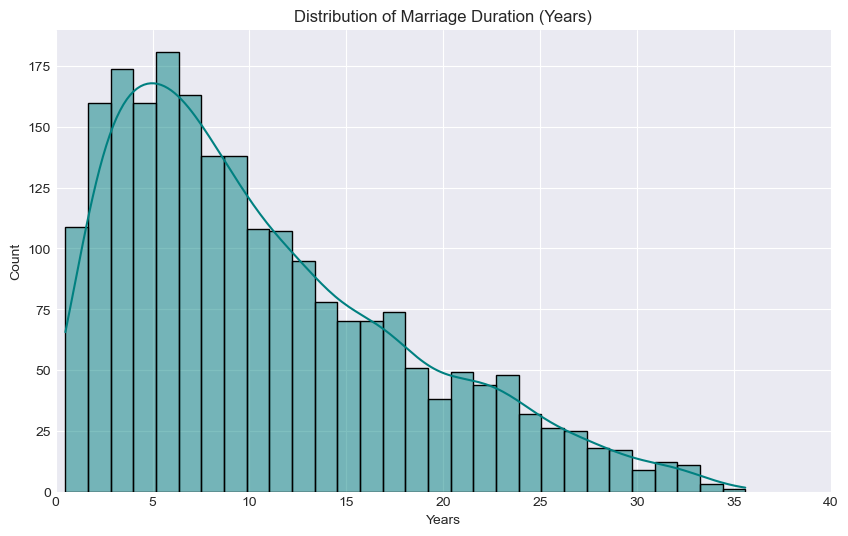

In [8]:
# Calculate duration in days, then convert to years
df['calculated_duration'] = (df['divorce_date'] - df['marriage_date']).dt.days / 365.25

# Histplot
plt.figure(figsize=(10, 6))
sns.histplot(df['calculated_duration'], bins=30, kde=True, color='teal')
plt.title('Distribution of Marriage Duration (Years)')
plt.xlabel('Years')
plt.xlim(0, 40)
plt.show()

### Age at Marriage vs. Divorce Risk

Let's see the age distribution of men and women at the time of marriage.

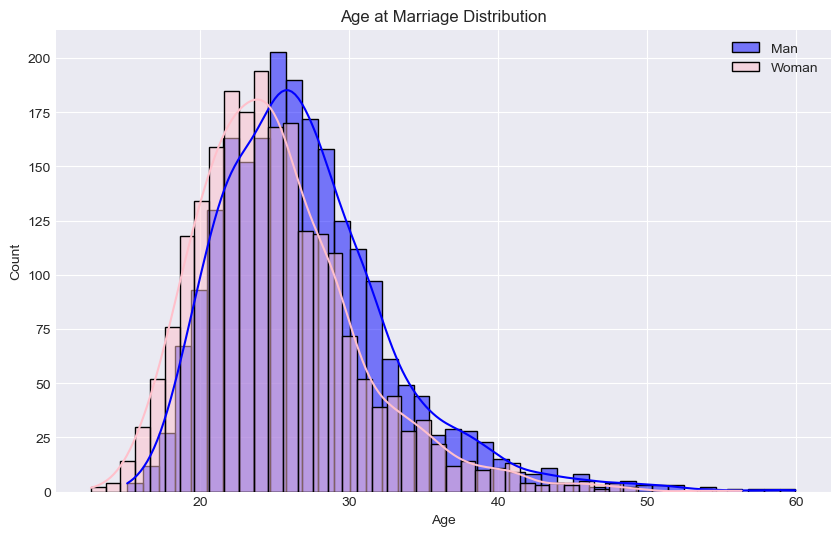

In [9]:
# Calculate Age at Marriage
df['man_age_at_marriage'] = (df['marriage_date'] - df['dob_man']).dt.days / 365.25
df['woman_age_at_marriage'] = (df['marriage_date'] - df['dob_woman']).dt.days / 365.25

# Drop invalid ages (e.g. negative or unrealistic)
df_age_clean = df[(df['man_age_at_marriage'] > 15) & (df['man_age_at_marriage'] < 100)]

plt.figure(figsize=(10, 6))
sns.histplot(df_age_clean['man_age_at_marriage'], color='blue', label='Man', kde=True, alpha=0.5)
sns.histplot(df_age_clean['woman_age_at_marriage'], color='pink', label='Woman', kde=True, alpha=0.5)
plt.title('Age at Marriage Distribution')
plt.xlabel('Age')
plt.legend()
plt.show()

---

## 7. Rolling Statistics (Moving Averages)

Data often has noise (random ups and downs). **Rolling Mean (Moving Average)** smooths this out to show the underlying trend clearly.

We will calculate a 3-year moving average for the yearly divorce count.

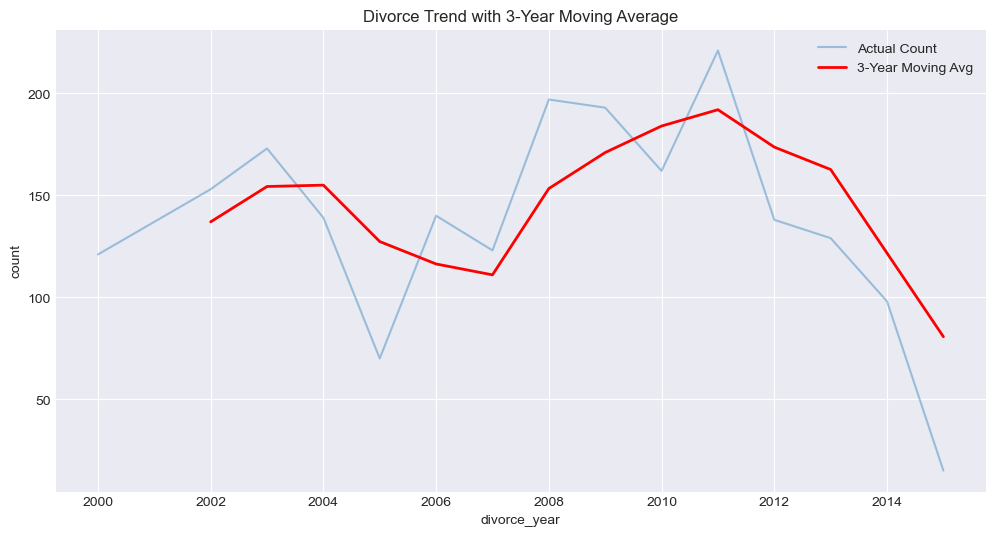

In [10]:
# Prepare Data: Sort by year
yearly_counts = df.groupby('divorce_year').size().reset_index(name='count')

# Calculate 3-Year Rolling Mean
yearly_counts['rolling_avg_3yr'] = yearly_counts['count'].rolling(window=3).mean()

# Plot
plt.figure(figsize=(12, 6))
sns.lineplot(data=yearly_counts, x='divorce_year', y='count', label='Actual Count', alpha=0.4)
sns.lineplot(data=yearly_counts, x='divorce_year', y='rolling_avg_3yr', label='3-Year Moving Avg', color='red', linewidth=2)

plt.title('Divorce Trend with 3-Year Moving Average')
plt.show()

In [ ]:
# ═══ CHECKPOINT — "Resampling Time Series Data" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('../../00-data/Divorce Data Analysis.csv')
date_cols = ['divorce_date', 'dob_man', 'dob_woman', 'marriage_date']
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')
df['divorce_year'] = df['divorce_date'].dt.year
df['divorce_month'] = df['divorce_date'].dt.month_name()
df['divorce_day_of_week'] = df['divorce_date'].dt.day_name()
df['marriage_year'] = df['marriage_date'].dt.year
df['marriage_month'] = df['marriage_date'].dt.month_name()
yearly_divorces = df['divorce_year'].value_counts().sort_index()
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['calculated_duration'] = (df['divorce_date'] - df['marriage_date']).dt.days / 365.25
df['man_age_at_marriage'] = (df['marriage_date'] - df['dob_man']).dt.days / 365.25
df['woman_age_at_marriage'] = (df['marriage_date'] - df['dob_woman']).dt.days / 365.25
df_age_clean = df[(df['man_age_at_marriage'] > 15) & (df['man_age_at_marriage'] < 100)]
yearly_counts = df.groupby('divorce_year').size().reset_index(name='count')
yearly_counts['rolling_avg_3yr'] = yearly_counts['count'].rolling(window=3).mean()

print("Checkpoint restored. Ready for: Resampling Time Series Data")

## 7.5 Resampling Time Series Data

Resampling allows us to change the frequency of our time series (e.g., daily to monthly).

### Common Resampling Operations:
- **Downsampling**: Higher frequency to Lower frequency (daily to monthly)
- **Upsampling**: Lower frequency to Higher frequency (monthly to daily)

**Common frequency codes:**
- `'D'` = Daily, `'W'` = Weekly, `'M'` = Monthly
- `'Q'` = Quarterly, `'Y'` = Yearly

In [ ]:
# Create a time-indexed dataframe for resampling
df_time = df.set_index('divorce_date').sort_index()

# Resample to monthly counts
monthly_divorces = df_time.resample('M').size()

# Resample to quarterly
quarterly_divorces = df_time.resample('Q').size()

# Plot comparison
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

monthly_divorces.plot(ax=axes[0], title='Monthly Divorce Counts')
axes[0].set_ylabel('Count')

quarterly_divorces.plot(ax=axes[1], title='Quarterly Divorce Counts', color='orange')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

## 7.6 Year-over-Year (YoY) Analysis

Year-over-Year analysis compares the same period across different years, helping identify growth or decline patterns.

In [ ]:
# TODO: compute `yearly`, `yoy_change`, `result`
# Hint: calculate_yoy, plt.figure, plt.bar, plt.axhline, plt.title
# Name your result: yearly, yoy_change, result, yoy_divorces

---

## 8. Exercises

### Exercise 1: Monthly Marriage Trends
1. Create a count plot to visualize which months have the highest number of **marriages** (`marriage_month`).
2. Compare it with the divorce month plot. Are the peak months different?

In [11]:
# Your code here


### Exercise 2: Income Trend Over Time
1. Group the data by `divorce_year`.
2. Calculate the average `income_man` for each year.
3. Plot a line chart to see if the average income of divorced men has changed over time.

In [ ]:
# Your code here


In [ ]:
# ═══ CHECKPOINT — "Exercise 3: Quarterly Analysis" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('../../00-data/Divorce Data Analysis.csv')
date_cols = ['divorce_date', 'dob_man', 'dob_woman', 'marriage_date']
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')
df['divorce_year'] = df['divorce_date'].dt.year
df['divorce_month'] = df['divorce_date'].dt.month_name()
df['divorce_day_of_week'] = df['divorce_date'].dt.day_name()
df['marriage_year'] = df['marriage_date'].dt.year
df['marriage_month'] = df['marriage_date'].dt.month_name()
yearly_divorces = df['divorce_year'].value_counts().sort_index()
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['calculated_duration'] = (df['divorce_date'] - df['marriage_date']).dt.days / 365.25
df['man_age_at_marriage'] = (df['marriage_date'] - df['dob_man']).dt.days / 365.25
df['woman_age_at_marriage'] = (df['marriage_date'] - df['dob_woman']).dt.days / 365.25
df_age_clean = df[(df['man_age_at_marriage'] > 15) & (df['man_age_at_marriage'] < 100)]
yearly_counts = df.groupby('divorce_year').size().reset_index(name='count')
yearly_counts['rolling_avg_3yr'] = yearly_counts['count'].rolling(window=3).mean()
df_time = df.set_index('divorce_date').sort_index()
monthly_divorces = df_time.resample('M').size()
quarterly_divorces = df_time.resample('Q').size()
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
def calculate_yoy(df, date_col):
    """
    Calculate year-over-year changes for record counts.
    Returns a DataFrame with yearly counts and YoY percentage change.
    """
    yearly = df.groupby(df[date_col].dt.year).size()
    yoy_change = yearly.pct_change() * 100
    result = pd.DataFrame({'Count': yearly, 'YoY Change (%)': yoy_change.round(2)})
    return result
yoy_divorces = calculate_yoy(df, 'divorce_date')
colors = ['green' if x > 0 else 'red' for x in yoy_divorces['YoY Change (%)'].fillna(0)]

print("Checkpoint restored. Ready for: Exercise 3: Quarterly Analysis")

### Exercise 3: Quarterly Analysis
1. Resample the divorce data to quarterly frequency
2. Identify which quarter historically has the most divorces
3. Create a heatmap showing divorces by year (rows) and quarter (columns)

**Hint**: Use `pivot_table` after extracting year and quarter from the divorce date.

In [ ]:
# Your code here

### Exercise 4: Cohort Analysis
Group couples by their `marriage_year` and analyze:
1. What is the average marriage duration for each marriage cohort?
2. Has marriage duration changed over time? (Are recent marriages lasting shorter/longer before divorce?)
3. Visualize this trend with a line plot.

**Hint**: Group by `marriage_year` and calculate the mean of `calculated_duration`.

In [ ]:
# Your code here

---

## 9. Conclusion

In this notebook, we explored temporal patterns:
- **Date Conversion**: Transforming strings to usable datetime objects.
- **Seasonality**: Identifying peak months for events.
- **Duration**: Calculating time lapses between two dates.
- **Smoothing**: Using rolling averages to identify real trends amidst noise.

**Next Steps**: Combine these temporal insights with missing data handling from the previous notebook for a robust analysis pipeline.